In [4]:
%pip install pandas numpy matplotlib seaborn

  Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl.metadata (6.6 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.7 MB 2.3 MB/s eta 0:00:05
   -- ------------------------------------- 0.8/10.7 MB 2.5 MB/s eta 0:00:04
   ---- ----------------------------------- 1.3/10.7 MB 2.1 MB/s eta 0:00:05
   ------ --------------------------------- 1.8/10.7 MB 2.2 MB/s eta 0:00:05
   ------- -------------------------------- 2.1/10.7 MB 2.1 MB/s eta 0:00:05
   --------- ------------------------------ 2.6/10.7 MB 2.1 MB/s eta 0:00:04
   ---------- ----------------------------- 2.9/10.7 MB 2.0 MB/s eta 0:00:04
   ------------ --------------------------- 3.4/10.7 MB 2.0 MB/s eta 0:00:04
   ------------- -------------------------- 3.7/10.7 MB 2.0 MB/s eta 0:00:04
   --------------- ------------------


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization style
sns.set_style("whitegrid")

# Display all columns
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the retail sales dataset

df = pd.read_csv("../data/raw/train.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 913000
Number of columns: 4


In [5]:
# Check dataset structure and data types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   date    913000 non-null  str  
 1   store   913000 non-null  int64
 2   item    913000 non-null  int64
 3   sales   913000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 27.9 MB


In [6]:
# Count missing values in each column

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
date     0
store    0
item     0
sales    0
dtype: int64


In [7]:
# Missing value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

date     0.0
store    0.0
item     0.0
sales    0.0
dtype: float64


In [8]:
# Count duplicate rows

print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [9]:
# Statistical summary of numerical columns

df.describe()

,store,item,sales
count,913000.000000,913000.000000,913000.000000
mean,5.500000,25.500000,52.250287
std,2.872283,14.430878,28.801144
min,1.000000,1.000000,0.000000
25%,3.000000,13.000000,30.000000
50%,5.500000,25.500000,47.000000
75%,8.000000,38.000000,70.000000
max,10.000000,50.000000,231.000000


In [10]:
# Convert date column into datetime format

df['date'] = pd.to_datetime(df['date'])

# Find date range
print("Starting Date:", df['date'].min())
print("Ending Date:", df['date'].max())

# Count unique stores and items
print("\nNumber of Stores:", df['store'].nunique())
print("Number of Items:", df['item'].nunique())

# Total sales
print("\nTotal Units Sold:", df['sales'].sum())

Starting Date: 2013-01-01 00:00:00
Ending Date: 2017-12-31 00:00:00

Number of Stores: 10
Number of Items: 50

Total Units Sold: 47704512


In [11]:
print("Date column datatype:", df['date'].dtype)

df[['date', 'store', 'item', 'sales']].head()

Date column datatype: datetime64[us]


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


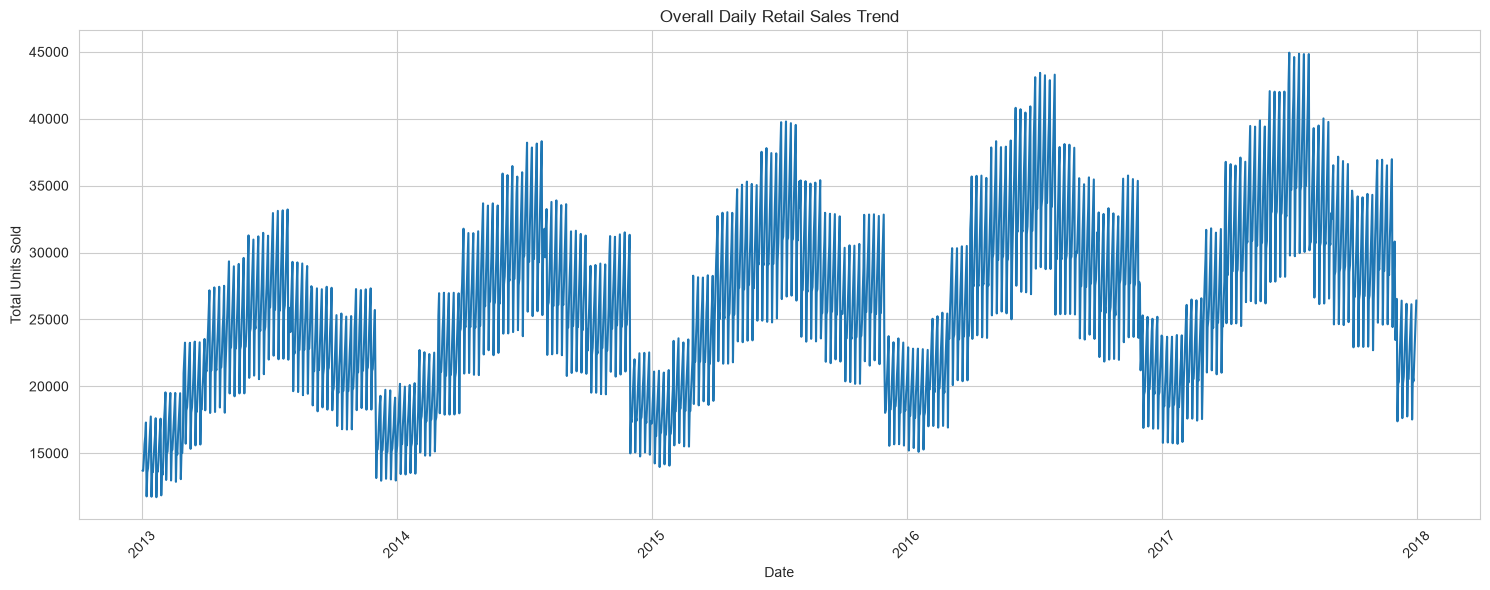

In [12]:
# Calculate total sales for each date

daily_sales = df.groupby('date')['sales'].sum()

# Create the line plot

plt.figure(figsize=(15, 6))

plt.plot(daily_sales.index, daily_sales.values)

plt.title("Overall Daily Retail Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

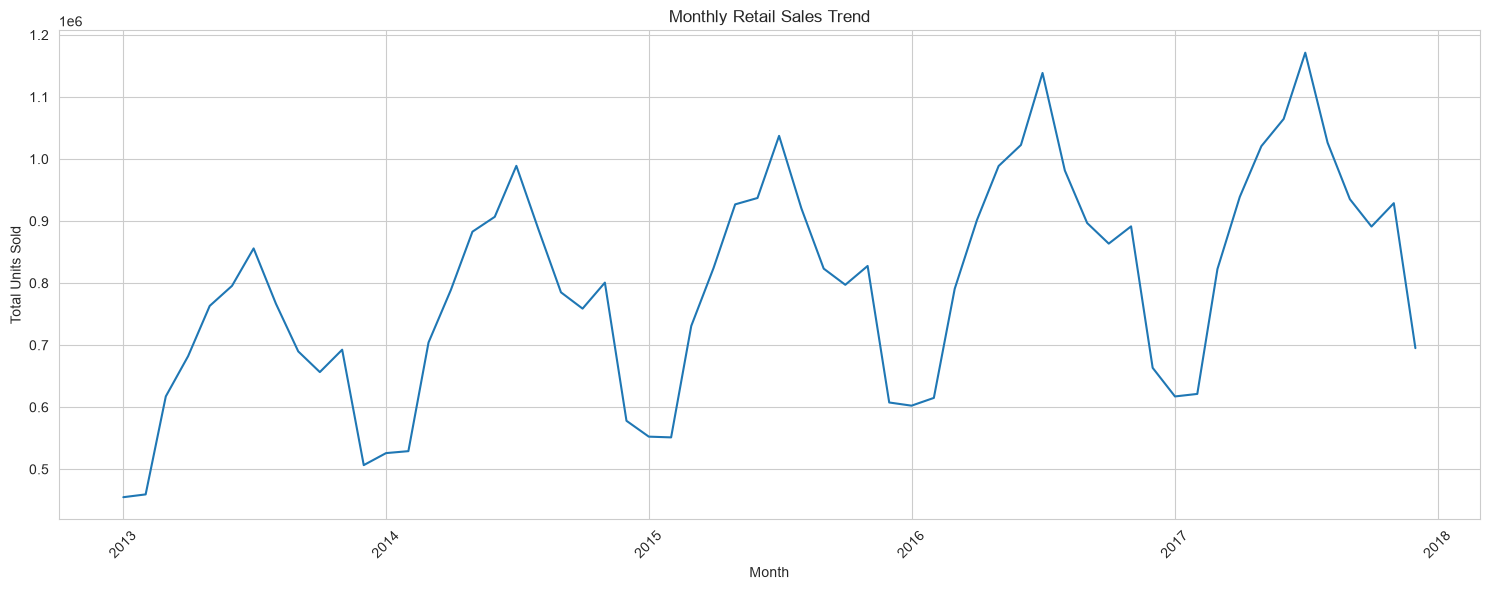

In [13]:
# Calculate total monthly sales

monthly_sales = df.resample(
    'MS',
    on='date'
)['sales'].sum()

# Plot monthly sales

plt.figure(figsize=(15, 6))

plt.plot(monthly_sales.index, monthly_sales.values)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [14]:
# Calculate total sales for each store

store_sales = df.groupby('store')['sales'].sum()

# Sort stores by sales

store_sales = store_sales.sort_values(ascending=False)

# Display store-wise sales

print(store_sales)

store
2     6120128
8     5856169
3     5435144
10    5360158
9     5025976
4     5012639
1     4315603
5     3631016
6     3627670
7     3320009
Name: sales, dtype: int64


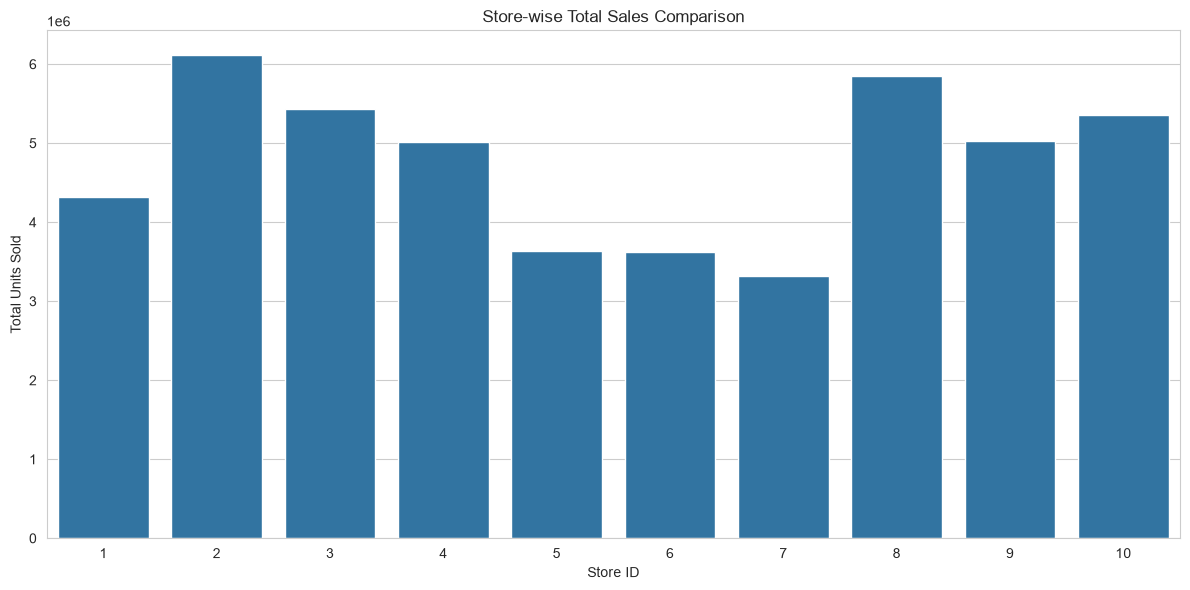

In [15]:
# Plot store-wise sales

plt.figure(figsize=(12, 6))

sns.barplot(
    x=store_sales.index,
    y=store_sales.values
)

plt.title("Store-wise Total Sales Comparison")
plt.xlabel("Store ID")
plt.ylabel("Total Units Sold")

plt.tight_layout()
plt.show()

In [16]:
# Calculate total sales for each item

item_sales = df.groupby('item')['sales'].sum()

# Sort items by sales

item_sales = item_sales.sort_values(ascending=False)

# Display top 10 items

print("Top 10 Best-Selling Items:")
print(item_sales.head(10))

print("\nBottom 10 Items:")
print(item_sales.tail(10))

Top 10 Best-Selling Items:
item
15    1607442
28    1604713
13    1539621
18    1538876
25    1473334
45    1471467
38    1470330
22    1469971
36    1406548
8     1405108
Name: sales, dtype: int64

Bottom 10 Items:
item
37    534258
40    534094
34    469935
16    468480
27    402628
4     401907
47    401781
41    401759
1     401384
5     335230
Name: sales, dtype: int64


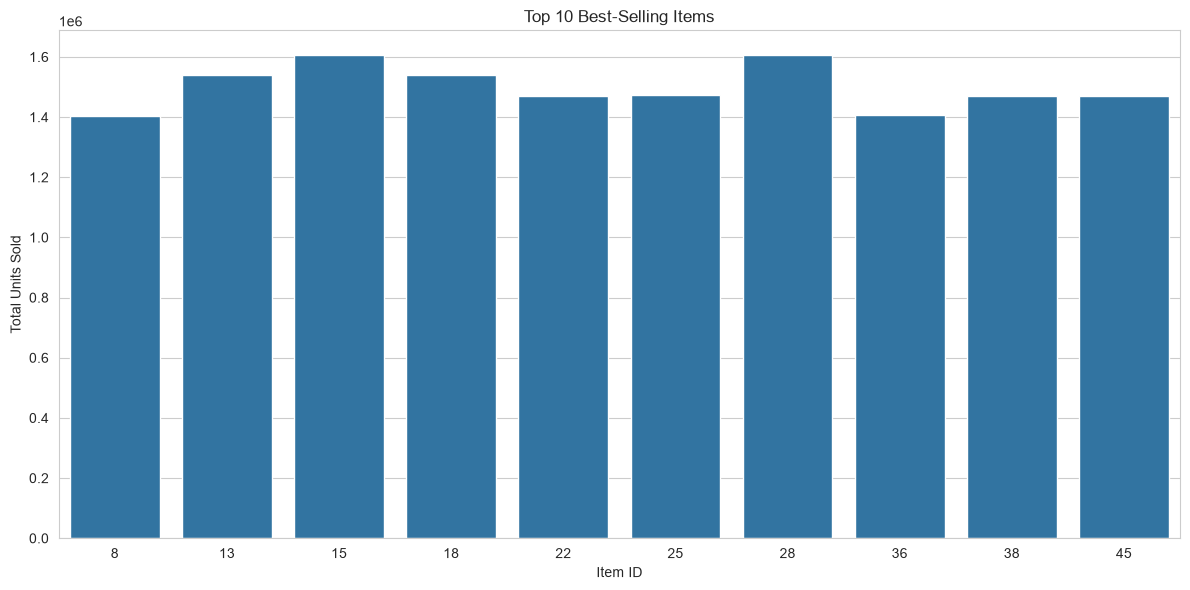

In [17]:
# Plot top 10 best-selling items

plt.figure(figsize=(12, 6))

sns.barplot(
    x=item_sales.head(10).index,
    y=item_sales.head(10).values
)

plt.title("Top 10 Best-Selling Items")
plt.xlabel("Item ID")
plt.ylabel("Total Units Sold")

plt.tight_layout()
plt.show()

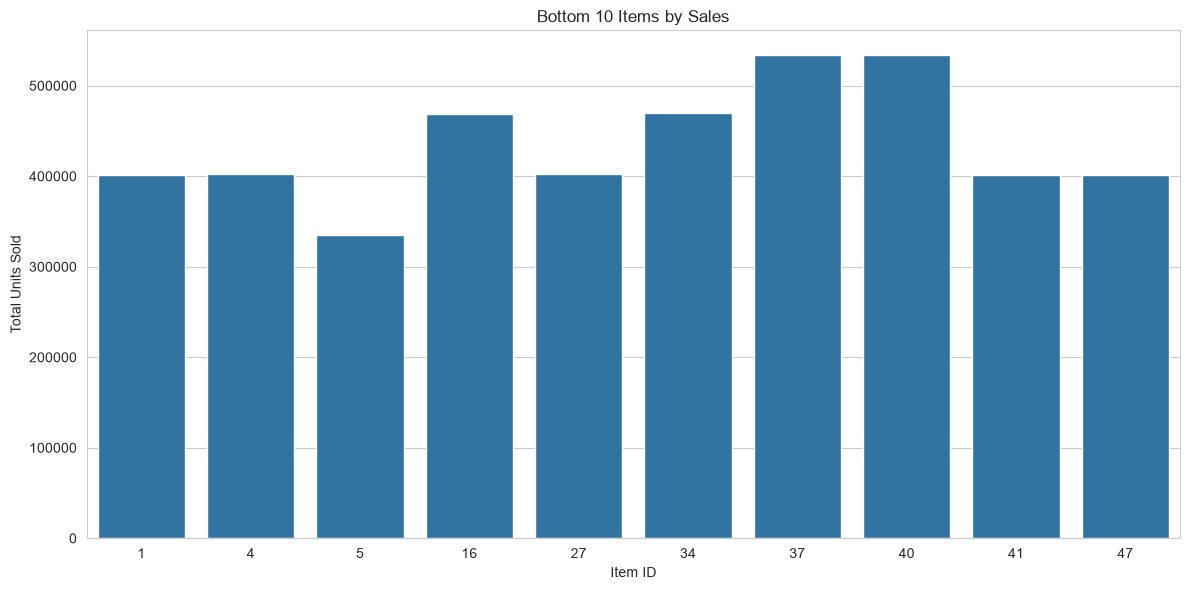

In [18]:
# Plot bottom 10 items

plt.figure(figsize=(12, 6))

sns.barplot(
    x=item_sales.tail(10).index,
    y=item_sales.tail(10).values
)

plt.title("Bottom 10 Items by Sales")
plt.xlabel("Item ID")
plt.ylabel("Total Units Sold")

plt.tight_layout()
plt.show()

In [19]:
# Extract day name from date

df['day_name'] = df['date'].dt.day_name()

# Calculate average sales for each weekday

weekday_sales = df.groupby('day_name')['sales'].mean()

# Arrange weekdays in correct order

weekday_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

weekday_sales = weekday_sales.reindex(weekday_order)

print("Average Sales by Weekday:")
print(weekday_sales)

Average Sales by Weekday:
day_name
Monday       41.429638
Tuesday      48.225908
Wednesday    48.368506
Thursday     51.723218
Friday       55.157249
Saturday     58.662697
Sunday       62.143333
Name: sales, dtype: float64


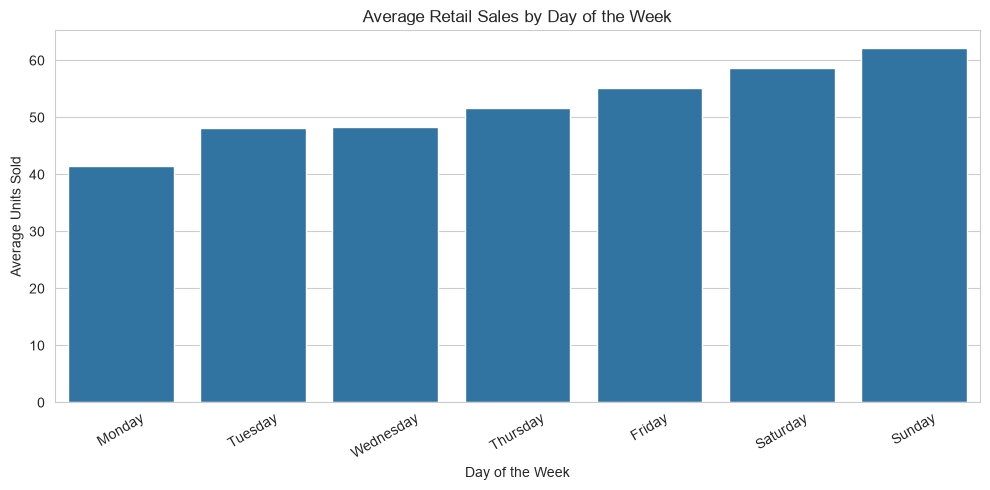

In [20]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values
)

plt.title("Average Retail Sales by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Units Sold")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
print("EDA Conclusion")
# EDA Conclusion

The dataset contains 913,000 records covering
10 stores and 50 unique items from January 2013
to December 2017.

The dataset contains no missing values or duplicate
records.

Key observations:

1. Retail sales show an overall increasing trend.
2. Monthly sales reveal recurring seasonal patterns.
3. Store 2 has the highest total sales.
4. Item 15 is the best-selling product.
5. Sunday has the highest average daily sales.
6. Monday has the lowest average daily sales.

These findings will guide our data preprocessing,
feature engineering and forecasting model development.

EDA Conclusion
